<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/03_SegmentIQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (200, 5)


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 200
Number of columns: 5


In [ ]:
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [ ]:
print(df.dtypes)

CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [ ]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
df["Gender_Encoded"] = df["Gender"].map({
    "Male": 0,
    "Female": 1
})

print(df[["Gender", "Gender_Encoded"]].head())

   Gender  Gender_Encoded
0    Male               0
1    Male               0
2  Female               1
3  Female               1
4  Female               1


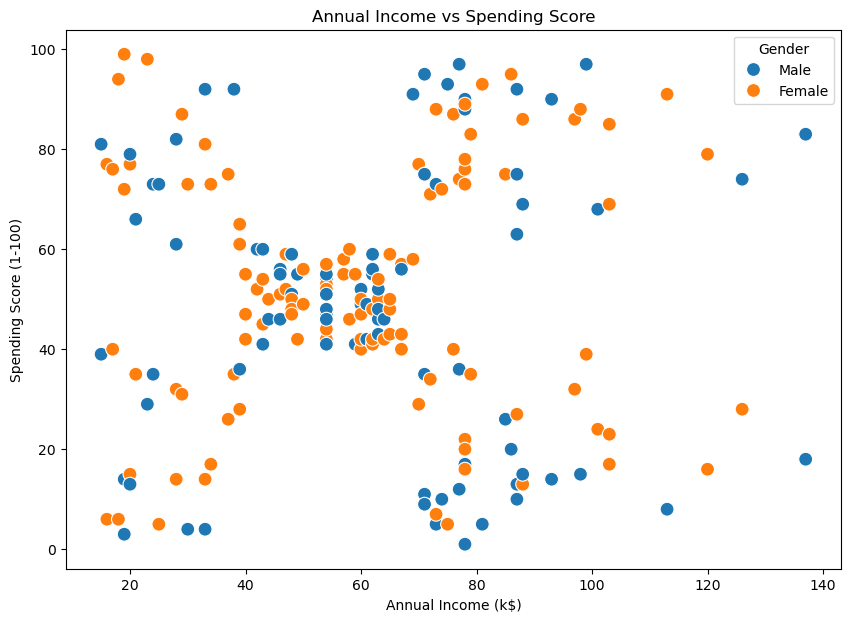

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=100
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Gender")

plt.show()

In [ ]:
X = df[
    [
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
]

print("Selected features:")
print(X.head())

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=[
        "Annual_Income_Scaled",
        "Spending_Score_Scaled"
    ]
)

print(X_scaled_df.head())

   Annual_Income_Scaled  Spending_Score_Scaled
0             -1.738999              -0.434801
1             -1.738999               1.195704
2             -1.700830              -1.715913
3             -1.700830               1.040418
4             -1.662660              -0.395980


In [ ]:
inertia = []

K_range = range(1, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

print("Inertia values:")
for k, value in zip(K_range, inertia):
    print(f"K = {k}: {value:.2f}")

Inertia values:
K = 1: 400.00
K = 2: 269.69
K = 3: 157.70
K = 4: 108.92
K = 5: 65.57
K = 6: 55.06
K = 7: 44.86
K = 8: 37.23
K = 9: 32.39
K = 10: 29.98


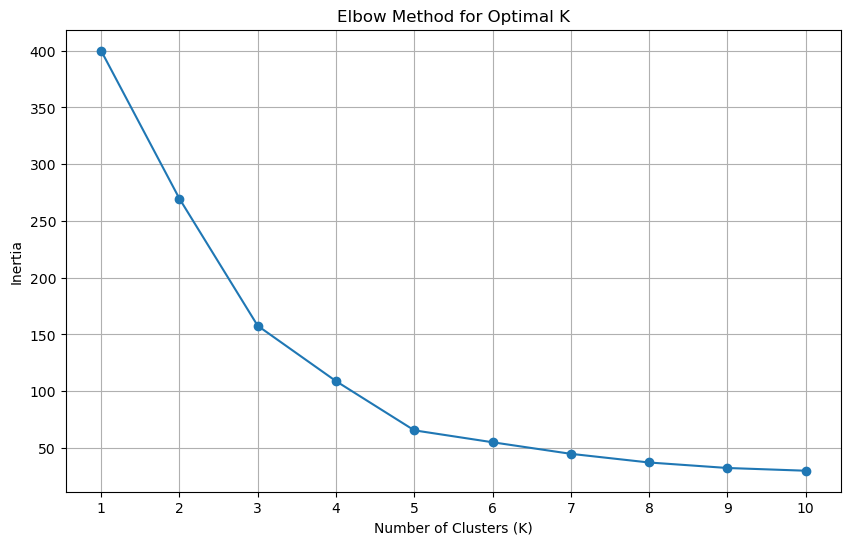

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K_range)

plt.grid(True)

plt.show()

In [ ]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.3213
K = 3: Silhouette Score = 0.4666
K = 4: Silhouette Score = 0.4939
K = 5: Silhouette Score = 0.5547
K = 6: Silhouette Score = 0.5399
K = 7: Silhouette Score = 0.5281
K = 8: Silhouette Score = 0.4552
K = 9: Silhouette Score = 0.4571
K = 10: Silhouette Score = 0.4432


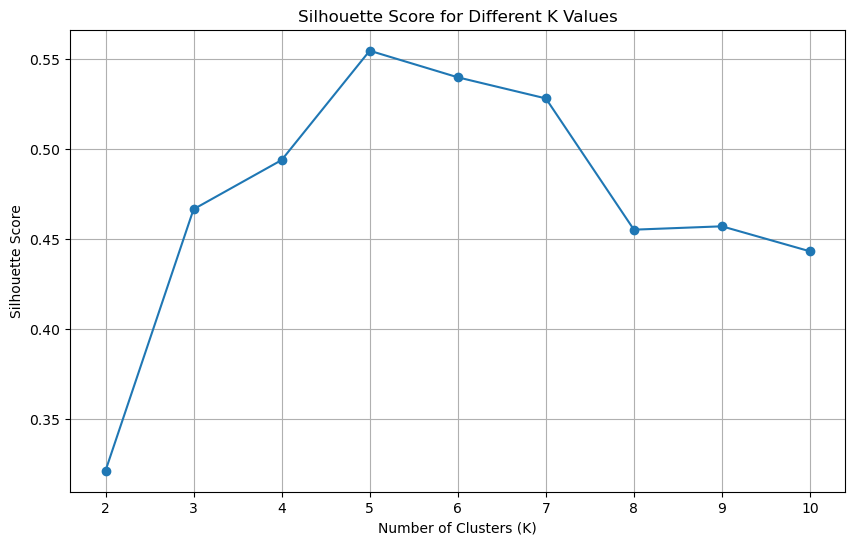

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [ ]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")

K-Means clustering completed.


In [ ]:
print(
    df[
        [
            "CustomerID",
            "Gender",
            "Age",
            "Annual Income (k$)",
            "Spending Score (1-100)",
            "Cluster"
        ]
    ].head(20)
)

    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0            1    Male   19                  15                      39   
1            2    Male   21                  15                      81   
2            3  Female   20                  16                       6   
3            4  Female   23                  16                      77   
4            5  Female   31                  17                      40   
5            6  Female   22                  17                      76   
6            7  Female   35                  18                       6   
7            8  Female   23                  18                      94   
8            9    Male   64                  19                       3   
9           10  Female   30                  19                      72   
10          11    Male   67                  19                      14   
11          12  Female   35                  19                      99   
12          13  Female   

In [ ]:
centroids_scaled = kmeans.cluster_centers_

centroids_original = scaler.inverse_transform(
    centroids_scaled
)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=[
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
)

centroid_df.index.name = "Cluster"

print("Cluster Centroids:")
print(centroid_df)

Cluster Centroids:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043


In [ ]:
cluster_counts = df["Cluster"].value_counts().sort_index()

print("Customers in each cluster:")
print(cluster_counts)

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [ ]:
cluster_summary = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean"
}).round(2)

print(cluster_summary)

           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        42.72               55.30                   49.52
1        32.69               86.54                   82.13
2        25.27               25.73                   79.36
3        41.11               88.20                   17.11
4        45.22               26.30                   20.91


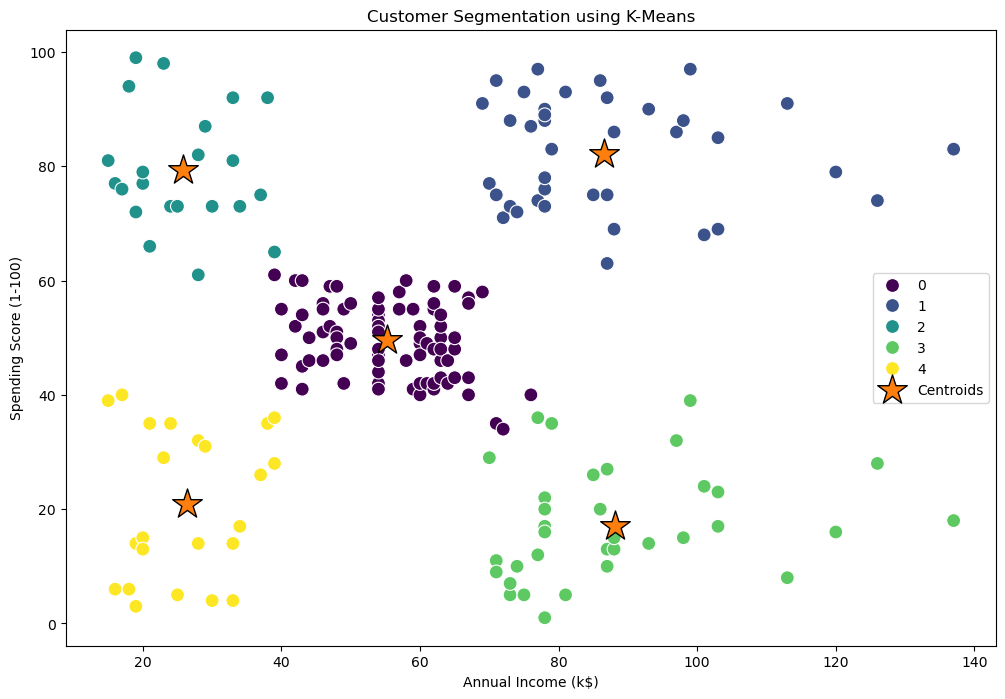

In [ ]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.scatter(
    centroid_df["Annual Income (k$)"],
    centroid_df["Spending Score (1-100)"],
    marker="*",
    s=500,
    edgecolor="black",
    label="Centroids"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()

plt.show()

In [ ]:
income_median = df["Annual Income (k$)"].median()
spending_median = df["Spending Score (1-100)"].median()

def assign_cluster_name(row):

    income = row["Annual Income (k$)"]
    spending = row["Spending Score (1-100)"]

    if income >= income_median and spending >= spending_median:
        return "High Income High Spenders"

    elif income >= income_median and spending < spending_median:
        return "High Income Low Spenders"

    elif income < income_median and spending >= spending_median:
        return "Low Income High Spenders"

    else:
        return "Low Income Low Spenders"


cluster_names = centroid_df.apply(
    assign_cluster_name,
    axis=1
)

cluster_name_mapping = dict(
    enumerate(cluster_names)
)

df["Cluster_Name"] = df["Cluster"].map(
    cluster_name_mapping
)

print(cluster_name_mapping)

{0: 'Low Income Low Spenders', 1: 'High Income High Spenders', 2: 'Low Income High Spenders', 3: 'High Income Low Spenders', 4: 'Low Income Low Spenders'}


In [ ]:
cluster_profile = centroid_df.copy()

cluster_profile["Cluster"] = cluster_profile.index

cluster_profile = cluster_profile.sort_values(
    [
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
)

print(cluster_profile)

         Annual Income (k$)  Spending Score (1-100)  Cluster
Cluster                                                     
2                 25.727273               79.363636        2
4                 26.304348               20.913043        4
0                 55.296296               49.518519        0
1                 86.538462               82.128205        1
3                 88.200000               17.114286        3


In [ ]:
persona_mapping = {
    0: "High Income High Spenders",
    1: "Low Income High Spenders",
    2: "Standard Customers",
    3: "Budget Conscious",
    4: "High Income Low Spenders"
}

df["Customer_Segment"] = df["Cluster"].map(
    persona_mapping
)

print(
    df[
        [
            "CustomerID",
            "Cluster",
            "Customer_Segment"
        ]
    ].head(20)
)

    CustomerID  Cluster          Customer_Segment
0            1        4  High Income Low Spenders
1            2        2        Standard Customers
2            3        4  High Income Low Spenders
3            4        2        Standard Customers
4            5        4  High Income Low Spenders
5            6        2        Standard Customers
6            7        4  High Income Low Spenders
7            8        2        Standard Customers
8            9        4  High Income Low Spenders
9           10        2        Standard Customers
10          11        4  High Income Low Spenders
11          12        2        Standard Customers
12          13        4  High Income Low Spenders
13          14        2        Standard Customers
14          15        4  High Income Low Spenders
15          16        2        Standard Customers
16          17        4  High Income Low Spenders
17          18        2        Standard Customers
18          19        4  High Income Low Spenders


In [ ]:
final_summary = df.groupby(
    "Customer_Segment"
).agg(
    Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

print(final_summary)

                           Customers  Average_Age  Average_Income  \
Customer_Segment                                                    
Budget Conscious                  35        41.11           88.20   
High Income High Spenders         81        42.72           55.30   
High Income Low Spenders          23        45.22           26.30   
Low Income High Spenders          39        32.69           86.54   
Standard Customers                22        25.27           25.73   

                           Average_Spending  
Customer_Segment                             
Budget Conscious                      17.11  
High Income High Spenders             49.52  
High Income Low Spenders              20.91  
Low Income High Spenders              82.13  
Standard Customers                    79.36  


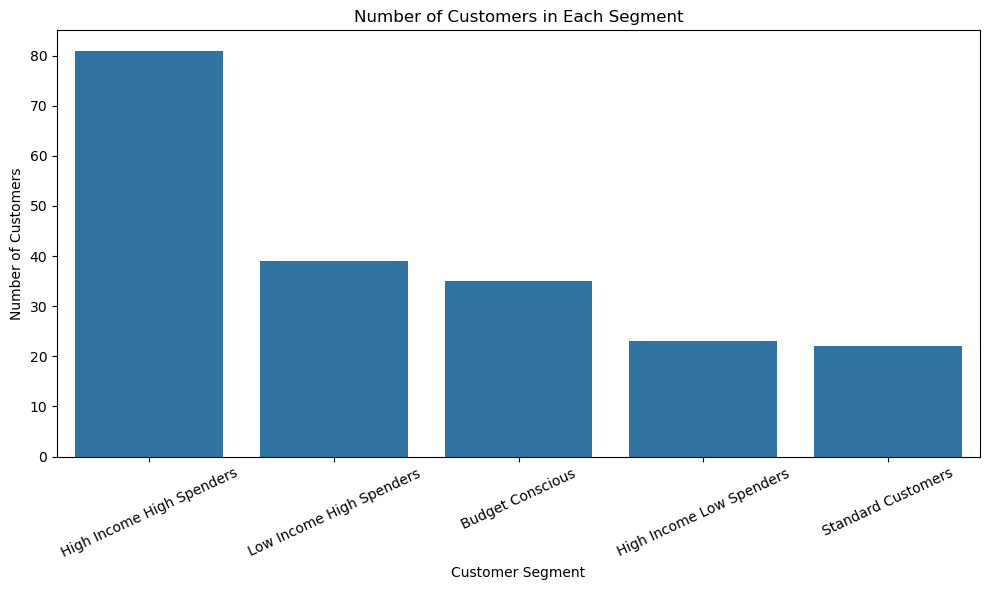

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Customer_Segment",
    order=df["Customer_Segment"].value_counts().index
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [ ]:
gender_cluster = pd.crosstab(
    df["Customer_Segment"],
    df["Gender"]
)

print(gender_cluster)

Gender                     Female  Male
Customer_Segment                       
Budget Conscious               16    19
High Income High Spenders      48    33
High Income Low Spenders       14     9
Low Income High Spenders       21    18
Standard Customers             13     9


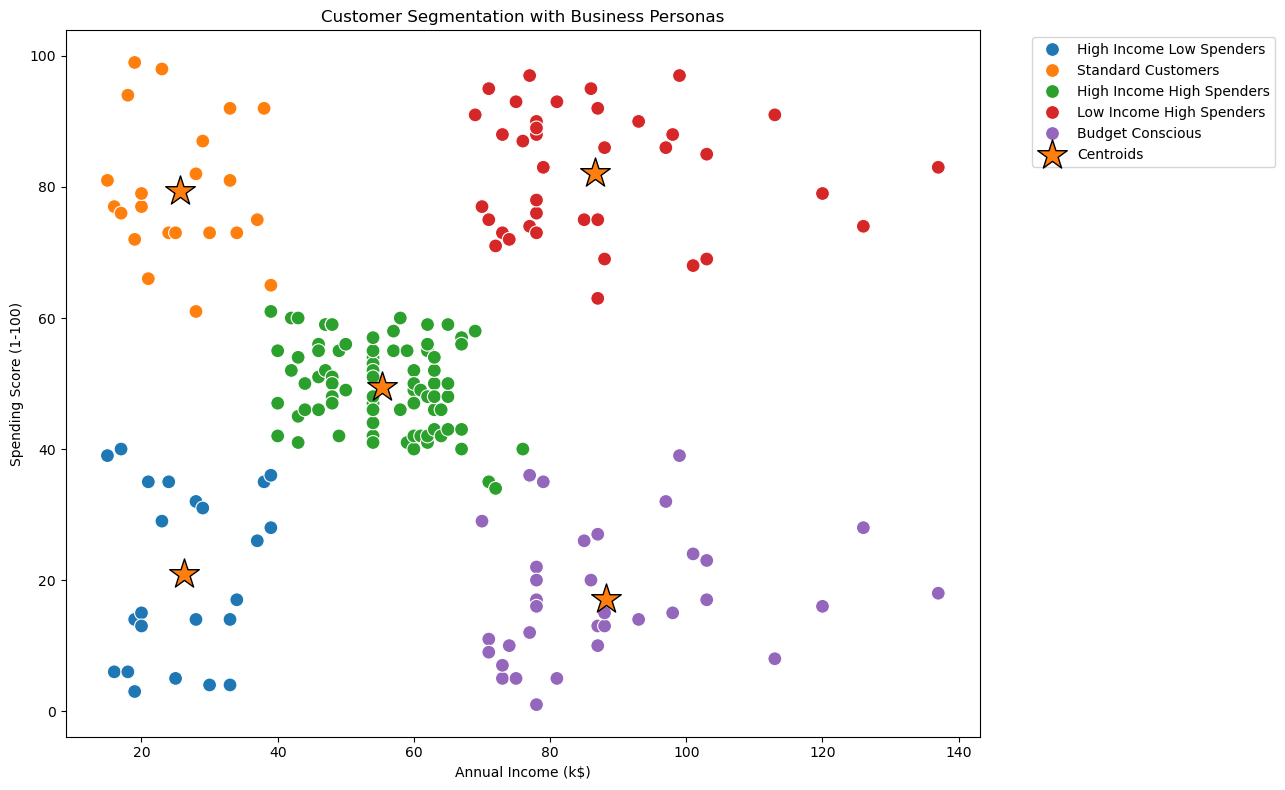

In [ ]:
plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Customer_Segment",
    s=100
)

plt.scatter(
    centroid_df["Annual Income (k$)"],
    centroid_df["Spending Score (1-100)"],
    marker="*",
    s=500,
    edgecolor="black",
    label="Centroids"
)

plt.title(
    "Customer Segmentation with Business Personas"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [ ]:
df.to_csv(
    "Mall_Customers_Segmented.csv",
    index=False
)

print("Segmented dataset saved successfully.")

Segmented dataset saved successfully.


In [ ]:
import joblib

joblib.dump(
    kmeans,
    "customer_segmentation_kmeans.pkl"
)

joblib.dump(
    scaler,
    "customer_segmentation_scaler.pkl"
)

print("K-Means model and scaler saved successfully.")

K-Means model and scaler saved successfully.


In [ ]:
loaded_kmeans = joblib.load(
    "customer_segmentation_kmeans.pkl"
)

loaded_scaler = joblib.load(
    "customer_segmentation_scaler.pkl"
)

print("Model loaded successfully.")

Model loaded successfully.


In [ ]:
new_customer = pd.DataFrame({
    "Annual Income (k$)": [75],
    "Spending Score (1-100)": [80]
})

new_customer_scaled = loaded_scaler.transform(
    new_customer
)

predicted_cluster = loaded_kmeans.predict(
    new_customer_scaled
)[0]

predicted_segment = cluster_name_mapping[
    predicted_cluster
]

print("Predicted Cluster:", predicted_cluster)
print("Predicted Segment:", predicted_segment)

Predicted Cluster: 1
Predicted Segment: High Income High Spenders


In [ ]:
print("=" * 70)
print("CUSTOMER SEGMENTATION PROJECT - FINAL SUMMARY")
print("=" * 70)

print("\nDataset Shape:", df.shape)

print("\nNumber of Clusters:", 5)

print("\nCluster Sizes:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster Centroids:")
print(centroid_df)

print("\nSilhouette Scores:")
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: {score:.4f}")

print("\nFinal Customer Segments:")
print(
    df["Customer_Segment"]
    .value_counts()
)

CUSTOMER SEGMENTATION PROJECT - FINAL SUMMARY

Dataset Shape: (200, 9)

Number of Clusters: 5

Cluster Sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster Centroids:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043

Silhouette Scores:
K=2: 0.3213
K=3: 0.4666
K=4: 0.4939
K=5: 0.5547
K=6: 0.5399
K=7: 0.5281
K=8: 0.4552
K=9: 0.4571
K=10: 0.4432

Final Customer Segments:
Customer_Segment
High Income High Spenders    81
Low Income High Spenders     39
Budget Conscious             35
High Income Low Spenders     23
Standard Customers           22
Name: count, dtype: int64
